# Kobayashi et al. · композиционное обобщение в контексте

Модель видит 64 примера одной функции и предсказывает её значение в новой точке. Каждую функцию задаёт взвешенная сумма двух матриц из шести. Например, пары $(0,1)$ и $(1,3)$ встречались при обучении, а $(0,3)$ впервые появляется на тесте. Сможет ли модель точно предсказывать значения функции и для новой пары? Так авторы проверяют композиционное обобщение.

**Vanilla Transformer** сразу предсказывает ответ по контексту и запросу. **Hypernetwork Transformer** выводит из контекста шесть коэффициентов. По ним гиперсеть строит матрицу первого слоя MLP, а MLP вычисляет ответ на запрос. Сравним обе модели на одних и тех же эпизодах. [Kobayashi et al., *When can transformers compositionally generalize in-context?*](https://arxiv.org/html/2407.12275v1)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
# Jupyter может начать работу в корне репозитория или в notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "icl_lab" / "runtime.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "icl_lab" / "runtime.py").is_file():
    raise RuntimeError("Откройте ноутбук из корня репозитория или каталога notebooks/.")
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
import kobayashi_notebook as lab

series_dir = ROOT / "artifacts/runs/kobayashi-jupyter-20261119"
variants = ("vanilla", "hypernetwork")
model_names = {"vanilla": "Vanilla Transformer", "hypernetwork": "Hypernetwork Transformer"}
seeds = (1, 2, 3)
%matplotlib inline

## Данные. Одна функция на один эпизод

Ответы генерирует **учитель**. У него шесть модулей — матрицы $\Theta_0,\ldots,\Theta_5\in\mathbb R^{16\times16}$ — и вектор выходных весов $r\in\mathbb R^{16}$. Эти параметры фиксированы для всего эксперимента. В каждом эпизоде учитель задаёт одну функцию $f_z:\mathbb R^{16}\to\mathbb R$. Обучаемая модель получает 64 примера и запрос $x_*$, для которого нужно предсказать $f_z(x_*)$.

1. **Выбрать код задачи** $z\in\mathbb R^6$. Генератор равновероятно выбирает одну разрешённую неупорядоченную пару модулей $(i,j)$. Для двух активных координат берёт независимые $s_i,s_j\sim\mathrm{Exp}(1)$ и задаёт $z_m=\tfrac12(1+s_m/(s_i+s_j))$ при $m\in\{i,j\}$. Остальные четыре координаты $z$ равны нулю. Каждый из двух ненулевых коэффициентов $z$ лежит между 0,5 и 1. В сумме они дают 1,5.
2. **Задать веса сети для этого эпизода.** Функцию $f_z$ вычисляет MLP с одним скрытым слоем. До нормировки его матрица весов равна $W_z=z_i\Theta_i+z_j\Theta_j$. Для нормировки делим $W_z$ на её наибольшее сингулярное значение $\lVert W_z\rVert_2$. Затем умножаем матрицу на $x$, применяем GELU покоординатно и берём скалярное произведение с $r$.

   $$
   f_z(x)=r^\top\,\mathrm{GELU}\!\left(\frac{W_z}{\lVert W_z\rVert_2}x\right).
   $$

3. **Составить контекст и запрос.** Генератор независимо выбирает координаты 65 векторов из $\mathrm{Uniform}[-\sqrt3,\sqrt3]$. Для всех векторов учитель использует одну и ту же $f_z$. В **контекст** попадают первые 64 пары $(x_t,f_z(x_t))$. От последнего примера модель получает только запрос $x_*$. Значение $y_*=f_z(x_*)$ служит целевым ответом. Генератор сохраняет код $z$ и номера модулей для анализа. Модель видит только контекст и запрос. Длина контекста в 64 примера — выбор нашей реализации. [Генератор эпизодов](../src/icl_lab/tasks/kobayashi.py) · [Протокол](../experiments/kobayashi-implementation.md)

### Один сохранённый эпизод

В эпизоде 0 тестового набора `test` активны модули 2 и 5. Коэффициенты $z_2$ и $z_5$ равны примерно 0,6341 и 0,8659. Первый вектор начинается с $(1{,}6417;\ 0{,}1380;\ 1{,}4166;\ -0{,}1196;\ldots)$. Учитель дал для него ответ $-0{,}4472$ — первая демонстрация готова. Для запроса из того же эпизода правильный ответ равен $0{,}1222$.

В таблице откройте **«Весь вход модели»**, чтобы увидеть все 64 пары и запрос: 16 координат в каждой строке и ответ учителя для каждой демонстрации. У запроса ячейка ответа оставлена пустой. Для просмотра другого эпизода поменяйте `row`. В `episode` доступны числа до округления.

In [2]:
from IPython.display import HTML

row = 0
episode = lab.inspect_episode(series_dir, seed=1, split="test", row=row)
x = np.asarray(episode["x"])
inputs = pd.DataFrame(x, columns=[f"x[{j}]" for j in range(x.shape[1])])
inputs.index = [f"Контекст {i + 1}" for i in range(len(x) - 1)] + ["Запрос"]
inputs["y в контексте"] = [*episode["context_y"], np.nan]

print(f"Эпизод {episode['episode_id']}, модули {episode['pair']}, z = {np.round(episode['z'], 4)}")
print(f"Целевое значение y* для запроса: {episode['y']:.6f}")
display(inputs.iloc[[0, 1, -1], [0, 1, 2, 3, -1]].style.format("{:.4f}", na_rep="—"))
full_input = inputs.to_html(float_format=lambda v: f"{v:.4f}", na_rep="—", max_rows=None, max_cols=None)
display(HTML(f"<details><summary>Весь вход модели · {len(inputs) - 1} демонстрации и запрос</summary>{full_input}</details>"))

Эпизод 0, модули [2, 5], z = [0.     0.     0.6341 0.     0.     0.8659]
Целевое значение y* для запроса: 0.122158


,x[0],x[1],x[2],x[3],y в контексте
Контекст 1,1.6417,0.1380,1.4166,-0.1196,-0.4472
Контекст 2,-0.4295,1.0155,0.0552,-1.4916,-0.5018
Запрос,0.8859,0.3650,0.1102,-1.4604,—


,x[0],x[1],x[2],x[3],x[4],x[5],x[6],x[7],x[8],x[9],x[10],x[11],x[12],x[13],x[14],x[15],y в контексте
Контекст 1,1.6417,0.1380,1.4166,-0.1196,-1.6857,-1.1925,0.2691,0.7053,1.1619,1.6812,0.1380,1.4674,1.4532,-0.1448,-1.3343,-1.1569,-0.4472
Контекст 2,-0.4295,1.0155,0.0552,-1.4916,-0.7672,-1.4094,-0.8727,-0.5358,-1.4052,-1.6415,-1.4881,0.5844,-1.3152,0.5891,1.7182,0.9740,-0.5018
Контекст 3,1.6972,0.7968,-0.1992,-1.2125,0.7326,-0.6175,-0.3186,-0.4853,-0.0426,-0.5829,-0.2711,-0.5469,0.0460,1.6970,-1.4866,-0.7653,-0.0292
Контекст 4,-0.6969,-0.0272,-0.7222,1.2034,-1.6789,-0.3970,-0.7467,1.7307,-0.7522,-1.0178,-1.3133,-1.3979,0.8599,-0.1575,-0.1764,-0.3671,-0.1208
Контекст 5,-0.7470,-0.6993,-0.9257,-0.1806,-0.2120,0.3928,-1.5576,1.0937,-1.6543,0.8439,-0.3378,-0.9097,0.2023,1.1628,-0.8177,-1.5898,0.2306
Контекст 6,0.0035,-1.4413,-1.2253,1.1736,-0.1205,-1.0777,-1.6762,-1.2261,-1.5936,1.0790,-1.2610,0.3584,1.5567,-1.6803,-0.7617,-1.5761,0.0063
Контекст 7,-1.0326,-0.5299,-1.5033,-1.3331,1.1617,-0.3298,0.4368,0.1724,0.7689,-0.4656,-0.6435,0.7020,0.8052,0.4657,-0.7129,-1.3066,-0.1984
Контекст 8,0.6122,0.7378,0.4673,0.7536,1.2850,1.4038,-0.2721,0.3117,-0.5995,0.0609,0.3206,-0.3686,-1.3416,1.3753,-1.5777,-1.3995,0.9442
Контекст 9,1.6122,1.1042,0.5782,0.2040,-1.3793,-0.3561,0.4766,-0.9305,0.9696,1.5684,0.9837,0.0101,-0.1988,-0.0751,1.7187,-1.1525,-0.2804
Контекст 10,-0.3330,1.0152,-1.6000,1.0708,1.4390,1.1470,-1.5064,1.3877,0.8744,-1.4078,1.6629,-0.9472,0.7129,-0.6709,1.5831,-0.4740,0.3625


## Какие пары модулей попадают в обучение и тест?

Из шести модулей можно составить $\binom{6}{2}=15$ пар. Пару кодирует **бинарная маска** длины 6. Единицы стоят в двух позициях, где $z$ отличен от нуля. Сами коэффициенты $z$ генератор выбирает заново для каждого эпизода.

**Connected+** — набор из 12 обучающих пар в статье. На рисунке вершины — модули, рёбра — пары из тестовых данных. Слева показаны новые эпизоды на парах из обучения — это тест **ID**. Справа показан тест **OOD** на трёх отложенных парах $(0,3)$, $(1,4)$ и $(2,5)$. Распределение входов $x$ в обоих тестах одинаково. Модули пронумерованы от 0 до 5. [Разбиение в статье, табл. 1](https://arxiv.org/html/2407.12275v1#A3.SS2)

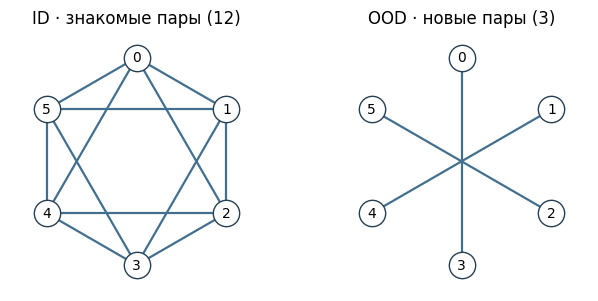

In [3]:
banks = series_dir / "vanilla" / f"seed-{seeds[0]}" / "banks"
angle = np.pi / 2 - np.arange(6) * np.pi / 3
xy = np.column_stack([np.cos(angle), np.sin(angle)])
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.9), layout="constrained")
for ax, split, title in zip(axes, ["id_test", "test"], ["ID · знакомые пары", "OOD · новые пары"]):
    with np.load(banks / f"{split}.npz") as bank:
        masks = np.unique(bank["mask"], axis=0)
    for mask in masks:
        i, j = np.flatnonzero(mask)
        ax.plot(*xy[[i, j]].T, color="#426f8e", linewidth=1.6, zorder=1)
    ax.scatter(*xy.T, s=360, color="white", edgecolor="#263f52", zorder=2)
    for index, (x, y) in enumerate(xy):
        ax.text(x, y, str(index), ha="center", va="center")
    ax.set(aspect="equal", xlim=(-1.22, 1.22), ylim=(-1.25, 1.25), title=f"{title} ({len(masks)})")
    ax.axis("off")
plt.show()

## Как Vanilla Transformer и Hypernetwork Transformer вычисляют прогноз?

Обе модели обучаются на одних и тех же эпизодах. Функция потерь — MSE по запросам батча, то есть среднее значение $(\hat y_*-y_*)^2$. Каждая пара $(x_t,y_t)$ образует один 17-мерный токен. У каждой модели два блока трансформера, в каждом по четыре головы self-attention. Каждый токен видит все позиции. К оценке внимания до softmax прибавляется обучаемое смещение, которое зависит от расстояния между позициями и их порядка.

| | Vanilla Transformer | Hypernetwork Transformer |
|---|---|---|
| Вход трансформера | 64 контекстных примера и токен запроса $(x_*,0)$. Размерность скрытого состояния 128. | Те же 64 примера и завершающий нулевой токен. Размерность скрытого состояния 64. |
| Выход в последней позиции | Линейный слой преобразует скрытое состояние в прогноз $\hat y_*$. | Линейный слой преобразует скрытое состояние в вектор $h\in\mathbb R^6$. Он зависит только от контекста. |
| Где используется запрос $x_*$ | Токен запроса участвует в self-attention. | Линейная гиперсеть по $h$ формирует матрицу $W(h)=\sum_m h_m B_m$. MLP умножает $W(h)$ на $x_*$, применяет GELU и линейным слоем выдаёт прогноз. |

У модели с гиперсетью шесть матриц $B_m\in\mathbb R^{32\times16}$ и вектор весов выходного слоя обучаются с нуля вместе с трансформером. Коэффициенты $h$ вычисляются заново для каждого эпизода. Истинный код задачи $z$ в функцию потерь не входит, поэтому координаты $h$ могут иметь иной смысл, чем координаты $z$. [Реализация обеих моделей](../src/icl_lab/tasks/kobayashi.py) · [Конфигурация Vanilla Transformer](../configs/experiments/kobayashi.yaml) · [Конфигурация Hypernetwork Transformer](../configs/experiments/kobayashi_hyper.yaml)

### Как обучались модели и как повторить запуск

На каждом шаге генератор создаёт 128 новых эпизодов на разрешённых парах. Для каждого запроса вычисляется квадрат разности между прогнозом модели и целевым значением учителя. Оптимизатор обновляет параметры модели по градиенту средней ошибки батча. Учитель фиксирован. В Hypernetwork Transformer градиент проходит через MLP и гиперсеть к трансформеру.

Каждую модель обучали оптимизатором AdamW в течение 100 000 шагов. Скорость обучения убывала от 0,001 по косинусному расписанию. Для каждой конфигурации сделано три запуска с разной инициализацией и потоком эпизодов. При одинаковом сиде обе архитектуры учатся на одном потоке эпизодов. *Weight decay* у Vanilla Transformer равен 0,1, у Hypernetwork Transformer — 0. [Vanilla YAML](../configs/experiments/kobayashi.yaml) · [Hypernetwork YAML](../configs/experiments/kobayashi_hyper.yaml)

**Запуск новой серии.** Выберите имя каталога `NEW_SERIES`, укажите `VARIANT = "vanilla"`, включите флаг и выполните только ячейку ниже. Модели для трёх сидов обучатся на MPS по очереди. Когда `vanilla/series-state.json` покажет `completed`, выполните эту же ячейку с `VARIANT = "hypernetwork"` и прежним именем каталога. После завершения обеих серий верните флаг в `False`, укажите новый каталог в `series_dir` в начале ноутбука и выполните **Run All**. [Скрипт запуска из ноутбука](../scripts/notebook_series.py) · [Обучение и оценка чекпойнтов](../scripts/run-kobayashi-series.py)

In [4]:
START_TRAINING = False
NEW_SERIES = "kobayashi-reader-01"
VARIANT = "vanilla"  # затем "hypernetwork"

if START_TRAINING:
    import sys
    from icl_lab.runtime import ROOT
    sys.path.insert(0, str(ROOT / "scripts"))
    from notebook_series import launch_series

    run_root = ROOT / "artifacts/runs" / NEW_SERIES / VARIANT
    state = launch_series(VARIANT, seeds=(1, 2, 3), run_root=run_root)
    print(state["state"], state.get("reason", ""), state["run_root"])
else:
    print("Открыта сохранённая серия. Для просмотра результатов можно продолжить.")

Открыта сохранённая серия. Для просмотра результатов можно продолжить.


### Что две модели ответили на этот запрос?

При чтении эпизода скрипт загрузил обе модели для запуска с `seed=1` по их конфигурациям и финальным весам `checkpoints/final.pt`, проверил совпадение тестовых эпизодов и заново вычислил целевые значения по сохранённым параметрам учителя. Затем он передал каждой модели только $x_1,\ldots,x_{64},x_*$ и $y_1,\ldots,y_{64}$ и вычислил прогноз на CPU. В таблице оба прогноза сравниваются с одним и тем же целевым значением. [Загрузка весов и инференс](../scripts/kobayashi_notebook.py)

In [5]:
answers = pd.Series(episode["predictions"], name="Предсказание").to_frame()
answers = answers.rename(index=model_names)
answers["Целевое значение"] = episode["y"]
answers["Абсолютная ошибка"] = (answers["Предсказание"] - episode["y"]).abs()
display(answers.style.format("{:.6f}"))

,Предсказание,Целевое значение,Абсолютная ошибка
Vanilla Transformer,0.063968,0.122158,0.058190
Hypernetwork Transformer,0.102788,0.122158,0.019370


## Насколько точны предсказания после обучения?

Для каждого из шести финальных чекпойнтов посчитаем ошибку на двух наборах по 2048 эпизодов. На **ID** комбинация модулей встречалась при обучении, но коэффициенты смеси и примеры выбраны заново. На **OOD** сама пара новая. Одинаковые эпизоды подаются всем моделям.

В эпизоде $e$ известны правильный ответ $y_e$, прогноз модели $\hat y_e$ и среднее по 64 ответам контекста $\bar y_e$. Это среднее берём за базовый прогноз. Для каждого тестового набора считаем
$$
\mathrm{MSE}=\frac{1}{n}\sum_e(\hat y_e-y_e)^2,\qquad
R^2_{\rm ctx}=1-\frac{\sum_e(\hat y_e-y_e)^2}{\sum_e(\bar y_e-y_e)^2}.
$$
При точном прогнозе на всех эпизодах $R^2_{\rm ctx}=1$, при той же MSE, что у базового прогноза, $R^2_{\rm ctx}=0$, а при большей ошибке оценка отрицательна. В приложении C.2 авторы описывают нормировку MSE через ошибку среднего по контексту. В нашей реализации сначала суммируются квадраты ошибок по эпизодам и затем берётся отношение сумм. В файлах запусков этот вариант метрики называется `paper_r2`.

Ячейка читает сохранённые ответы каждого чекпойнта, сверяет их с эпизодами тестового набора и пересчитывает обе метрики. В таблице показаны результаты последнего шага обучения для каждого запуска. [Метрика в статье, приложение C.2](https://arxiv.org/html/2407.12275v1#A3.SS2) · [Локальный протокол](../experiments/kobayashi-implementation.md)

In [6]:
history = lab.score_history(series_dir, variants, seeds)
final = history.loc[history["is_final"]].copy()
table = final.pivot(index=["variant", "seed"], columns="split", values=["mse", "paper_r2"])
table = table.rename(index=model_names, level="variant")
table = table.rename(columns={"mse": "MSE", "paper_r2": "R²_ctx", "id_test": "ID", "test": "OOD"})
display(table.rename_axis(index=["Модель", "Seed"], columns=[None, None]).round(6))

MSE              R²_ctx          
                                     ID       OOD        ID       OOD
Модель                   Seed                                        
Hypernetwork Transformer 1     0.000054  0.019696  0.999574  0.848232
                         2     0.000032  0.006769  0.999752  0.947839
                         3     0.000073  0.019829  0.999432  0.847210
Vanilla Transformer      1     0.000315  0.015751  0.997541  0.878631
                         2     0.000462  0.017212  0.996386  0.867374
                         3     0.000450  0.019273  0.996483  0.851496

## Сопоставление со статьёй · перенос на новые пары модулей

На рис. 2A у авторов Hypernetwork Transformer достигает меньшей ошибки на знакомых парах и точнее предсказывает значения функций на отложенных парах. Слева сравниваем MSE на знакомых парах, справа — $R^2_{\rm ctx}$ на трёх отложенных. Чем ниже кривая слева и выше справа, тем точнее модель. Каждая точка соответствует шагу, на котором сохранили веса. Цвет обозначает сид обучения.

Для этого сравнения авторы обучали модели на **Connected+** и оценивали перенос на 16 000 OOD-эпизодах. Наша серия использует тот же список пар, один фиксированный набор весов учителя и по 2048 эпизодов для ID и OOD. [Статья, рис. 2A и §3](https://arxiv.org/html/2407.12275v1#S3) · [Состав наборов, таблица 1](https://arxiv.org/html/2407.12275v1#A3.SS2)

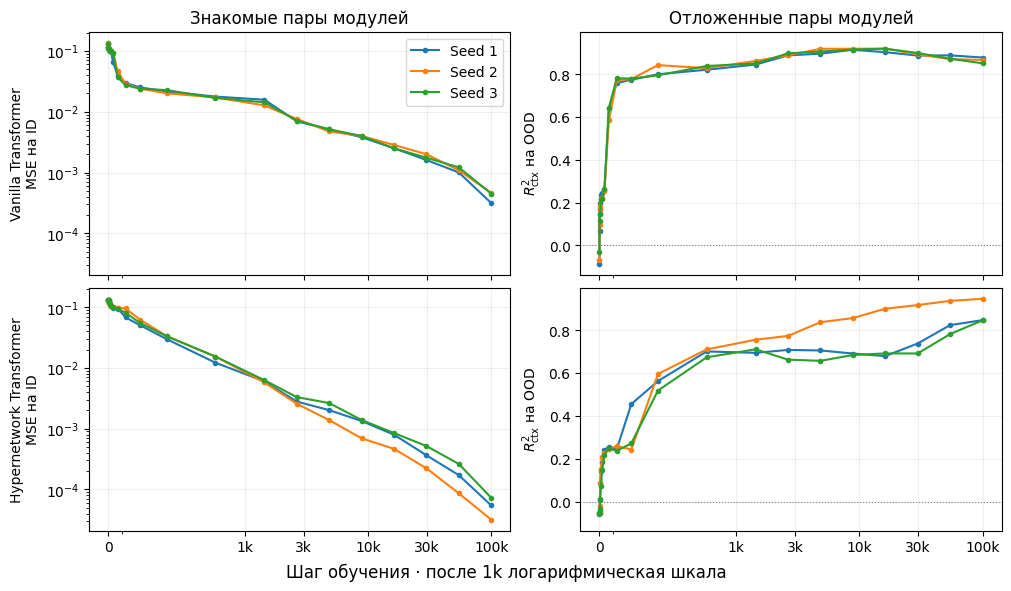

In [7]:
fig, axes = plt.subplots(len(variants), 2, sharex=True, sharey="col",
                         figsize=(10, 5.8), layout="constrained", squeeze=False)
for row, variant in enumerate(variants):
    for column, (split, metric) in enumerate([("id_test", "mse"), ("test", "paper_r2")]):
        ax = axes[row, column]
        group = history.query("variant == @variant and split == @split")
        for seed, curve in group.sort_values("step").groupby("seed"):
            ax.plot(curve["step"], curve[metric], marker=".", lw=1.5, label=f"Seed {seed}")
        ax.set_xscale("symlog", linthresh=1000)
        ax.set_xticks([0, 1000, 3000, 10000, 30000, 100000], ["0", "1k", "3k", "10k", "30k", "100k"])
        ax.grid(alpha=0.2)
    axes[row, 0].set_ylabel(f"{model_names[variant]}\nMSE на ID")
    axes[row, 0].set_yscale("log")
    axes[row, 1].set_ylabel(r"$R^2_{\mathrm{ctx}}$ на OOD")
    axes[row, 1].axhline(0, lw=0.8, color="grey", linestyle=":")
axes[0, 0].set_title("Знакомые пары модулей")
axes[0, 1].set_title("Отложенные пары модулей")
axes[0, 0].legend()
fig.supxlabel("Шаг обучения · после 1k логарифмическая шкала")
plt.show()

### Во всех ли запусках Hypernetwork Transformer точнее на OOD?

Для каждого из трёх запусков сравним модели, обученные на одном потоке эпизодов. Слева показан $R^2_{\rm ctx}$ обычного трансформера, справа — трансформера с гиперсетью. Линия поднимается, если у второй модели меньше суммарная квадратичная ошибка на тех же OOD-запросах. В легенде $\Delta$ — значение справа минус значение слева.

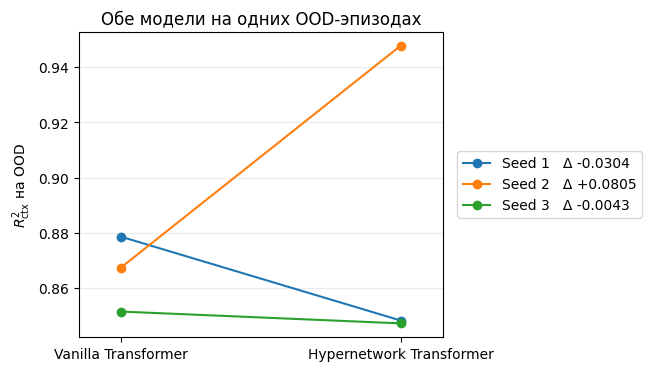

In [8]:
paired = final.query("split == 'test'").pivot(index="seed", columns="variant", values="paper_r2")
fig, ax = plt.subplots(figsize=(6.4, 3.6), layout="constrained")
for seed, row in paired.iterrows():
    difference = row["hypernetwork"] - row["vanilla"]
    ax.plot([0, 1], row[["vanilla", "hypernetwork"]], marker="o",
            label=f"Seed {seed}   Δ {difference:+.4f}")
ax.set_xticks([0, 1], [model_names[v] for v in variants])
ax.set(xlim=(-0.15, 1.15), ylabel=r"$R^2_{\mathrm{ctx}}$ на OOD", title="Обе модели на одних OOD-эпизодах")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

**Что повторилось в серии:** 

На знакомых парах модель с гиперсетью дала меньшую финальную MSE во всех трёх запусках. В среднем по трём запускам ошибка составила 0,000053 у модели с гиперсетью и 0,000409 у обычного трансформера. Это согласуется с нижней панелью рис. 2A.

**Где результаты разошлись:** 

Обе наши модели научились решать задачи и на новых парах. Средний OOD $R^2_{\rm ctx}$ составил 0,866 у обычного трансформера и 0,881 у модели с гиперсетью. Положительная средняя разность возникла за счёт запуска 2. В запусках 1 и 3 точнее оказался обычный трансформер. Выраженное преимущество модели с гиперсетью на OOD с верхней панели рис. 2A в этой серии устойчиво не повторилось.

Все шесть обучений используют одного учителя. У Vanilla Transformer размерность скрытого состояния равна 128 и weight decay — 0,1. У Hypernetwork Transformer эти значения равны 64 и 0. Сравнение относится к этим двум конфигурациям. Панели 2C и 2D статьи посвящены другим опытам — задачам от независимого учителя и изменению связности обучающих пар. Они выходят за рамки этой серии.

## Линейное декодирование. Можно ли восстановить код задачи $z$ из скрытого состояния?

На рис. 2B авторы обучили **линейный декодер** восстанавливать истинный код задачи $z$ по скрытым состояниям трансформера. Веса самого трансформера при этом фиксированы. Декодер обучался на 16 000 ID-эпизодов и проверялся на 16 000 OOD-эпизодов. Насколько точно можно восстановить код, даже если модель ошибается в прогнозе? Слева повторяем эту проверку на наших моделях. Справа — наш дополнительный эксперимент с восстановленным кодом. [Статья, рис. 2B и приложение C.2](https://arxiv.org/html/2407.12275v1#A3.SS2)

1. **Восстановить код.** По скрытому состоянию $s$ последнего токена на выбранном слое обучаем линейный декодер $\hat z=Ws+b$ предсказывать шесть координат $z$. У Vanilla Transformer последний токен содержит запрос. У Hypernetwork Transformer это нулевой токен на входе, и его скрытое состояние зависит только от контекста. Для обеих архитектур $\hat z$ — прогноз внешнего декодера. Внутренний вектор $h$ модель с гиперсетью вычисляет сама для своего прогноза $\hat y_*$.
2. **Выбрать слой и силу регуляризации.** Отдельно для входной проекции и для выхода каждого блока стандартизуем признаки и обучаем декодер на выборке `probe_train`. При обучении декодера добавляем к MSE штраф за сумму квадратов весов. В статье коэффициент штрафа равен 1. У нас слой и коэффициент выбираются по наименьшей MSE кода на ID-выборке `validation`. В исходной серии в каждой выборке 2048 эпизодов. На OOD для каждой координаты $z_m$ считаем обычный $R^2$ относительно её среднего по OOD-эпизодам. Среднее шести таких оценок обозначим $R^2_z$.
3. **Вычислить ответ по восстановленному коду.** Подставляем все шесть координат $\hat z$ в функцию учителя с известными матрицами $\Theta_m$ и вектором $r$, в том числе если ненулевых координат больше двух. Для прогноза $f_{\hat z}(x_*)$ считаем $R^2_{\rm ctx}$ относительно среднего ответа в контексте, как для предсказаний самих моделей. [Расчёт обеих метрик](../src/icl_lab/tasks/kobayashi.py)

На графике есть два контрольных условия. В первом при обучении декодера истинные коды $z$ перемешиваем между эпизодами. Во втором берём скрытые состояния случайно инициализированной необученной модели. В обоих случаях заново подбираем слой и силу регуляризации. Для каждой архитектуры использована одна случайная инициализация необученной модели, поэтому все три её точки совпадают по высоте.

In [9]:
from shlex import join

probe, missing = lab.probe_results(series_dir, variants, seeds)
for run in missing:
    print("Для расчёта финальной диагностики выполните команду из корня репозитория:")
    print(join(["./scripts/local-python", "-m", "icl_lab", "analyze",
                "--run-dir", str(run.relative_to(ROOT)), "--checkpoint", "last", "--device", "mps"]))

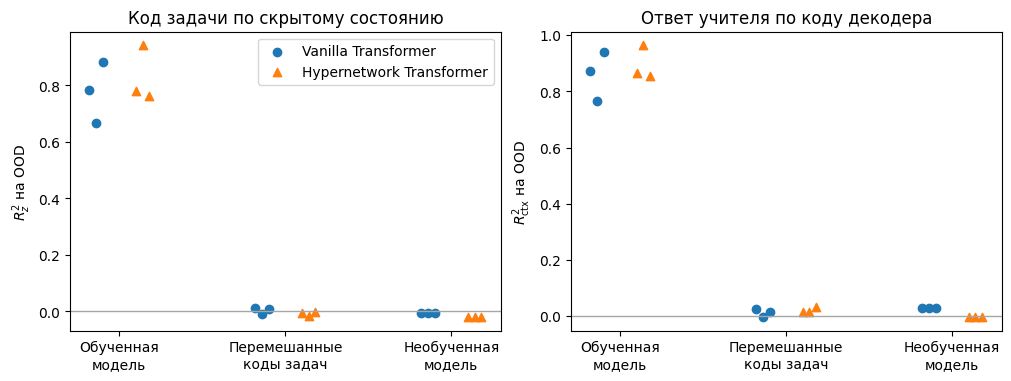

In [10]:
if not probe.empty:
    controls = {"trained_probe": "Обученная\nмодель", "shuffled_label_probe": "Перемешанные\nкоды задач",
                "untrained_model_probe": "Необученная\nмодель"}
    metrics = {
        "code_r2": ("Код задачи по скрытому состоянию", r"$R^2_z$ на OOD"),
        "executor_r2": ("Ответ учителя по коду декодера", r"$R^2_{\mathrm{ctx}}$ на OOD"),
    }
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    for ax, (metric, (title, ylabel)) in zip(axes, metrics.items()):
        for variant, offset, marker in [("vanilla", -0.14, "o"), ("hypernetwork", 0.14, "^")]:
            part = probe[probe.variant == variant]
            positions = part.control.map({key: i for i, key in enumerate(controls)})
            jitter = part.seed.map(dict(zip(seeds, np.linspace(-0.04, 0.04, len(seeds)))))
            ax.scatter(positions + offset + jitter, part[metric], marker=marker, label=model_names[variant])
        ax.axhline(0, color="0.65", lw=1)
        ax.set(xticks=range(len(controls)), xticklabels=list(controls.values()), title=title, ylabel=ylabel)
    axes[0].legend()
    plt.show()
    if probe.invalid.sum():
        print("Эпизодов с неопределённым ответом учителя:", probe.invalid.sum())

На трёх отложенных парах $R^2_z$ линейного декодера составляет 0,67–0,88 для Vanilla Transformer и 0,76–0,94 для Hypernetwork Transformer. Диапазоны отражают разброс по трём запускам. При перемешивании кодов и для необученных моделей $R^2_z$ близок к нулю. Значит, из скрытых состояний обученных моделей можно линейно восстановить информацию о коэффициентах $z$ даже на новых парах модулей.

В дополнительном опыте учитель по восстановленному коду даёт средний по трём запускам $R^2_{\rm ctx}=0{,}860$ для Vanilla Transformer и $0{,}895$ для Hypernetwork Transformer. Ответ учителя определён во всех проверенных эпизодах. Восстановленный код позволяет предсказывать значение функции, когда известны параметры учителя. Каким способом сами обученные модели используют эту информацию, остаётся открытым вопросом. [Результаты серии](../artifacts/records/kobayashi-mps-comparison-20261119.json)